In [1]:
from datetime import datetime
now = datetime.now()
print(f"Last updated: {now.month}/{now.day}/{now.year} {now.strftime('%I:%M%p').lstrip('0').lower()}")

Last updated: 2/13/2026 11:23pm


In [2]:
# Block 0 - Imports + Loading

import pandas as pd
import numpy as np
import matplotlib.pyplot ~~~~as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 6)

master_df = pd.read_csv("Master_Analytical_Table.csv")
seeds_df  = pd.read_csv("MNCAATourneySeeds.csv")
slots_df  = pd.read_csv("MNCAATourneySlots.csv")

print("Master shape:", master_df.shape)
print("Seeds shape:", seeds_df.shape)
print("Slots shape:", slots_df.shape)

master_df.head()


,Season,Is_Tourney,TeamA_ID,TeamB_ID,DIFF_EFG,DIFF_TOV,DIFF_ORB,DIFF_FTR,Win_A
0,2003,0,1104,1328,0.057417,5.250973,0.094771,-0.104750,1
1,2003,0,1393,1272,-0.080886,-1.315508,0.041667,-0.007944,0
2,2003,0,1437,1266,-0.160841,3.044810,0.107962,-0.184932,0
3,2003,0,1457,1296,-0.084586,12.253945,0.241453,-0.509667,0
4,2003,0,1400,1208,0.105500,6.147507,0.042878,-0.222369,1


In [3]:
# Block 1 - Quick for Sanity

needed = ["Season", "Is_Tourney", "TeamA_ID", "TeamB_ID", "DIFF_EFG", "DIFF_TOV", "DIFF_ORB", "DIFF_FTR", "Win_A"]
missing = [c for c in needed if c not in master_df.columns]
print("Missing:", missing)


Missing: []


Part A - Correlation Matrix

In [4]:
# Block A1 - Compute correlations

eda_cols = ["DIFF_EFG", "DIFF_TOV", "DIFF_ORB", "DIFF_FTR", "Win_A"]
corr = master_df[eda_cols].corr()
corr

,DIFF_EFG,DIFF_TOV,DIFF_ORB,DIFF_FTR,Win_A
DIFF_EFG,1.000000,0.042492,0.061784,0.201567,0.660288
DIFF_TOV,0.042492,1.000000,0.143923,0.043420,-0.244437
DIFF_ORB,0.061784,0.143923,1.000000,0.046606,0.253907
DIFF_FTR,0.201567,0.043420,0.046606,1.000000,0.395813
Win_A,0.660288,-0.244437,0.253907,0.395813,1.000000


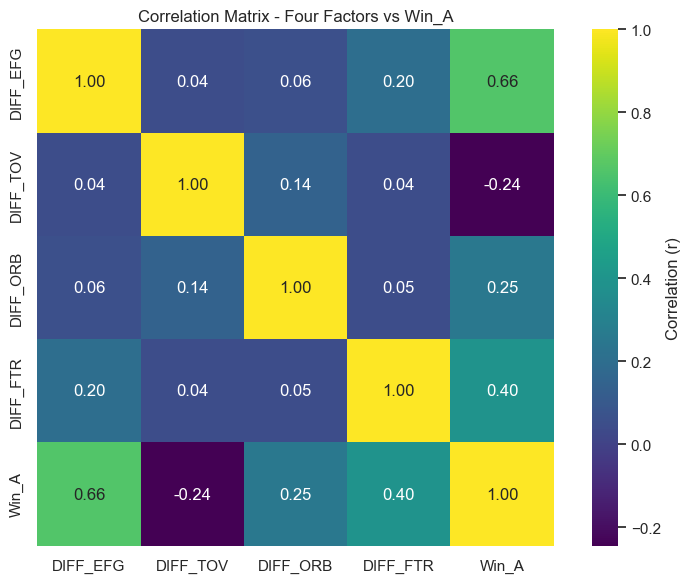

In [5]:
# Block A2 - Plot correlation heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", square=True, cbar_kws={"label":"Correlation (r)"})
plt.title("Correlation Matrix - Four Factors vs Win_A")
plt.tight_layout()
plt.show()

In [6]:
#Block A3 - Identify strongest predictor

corr_with_win = corr["Win_A"].drop("Win_A")
corr_sorted = corr_with_win.reindex(corr_with_win.abs().sort_values(ascending=False).index)

print("Correlation with Win_A (sorted by |r|):")
print(corr_sorted)

top2 = corr_with_win.abs().sort_values(ascending=False).head(2).index.tolist()
print("\nTop 2 features:", top2)

print("\nShooting vs Ball Security:")
print("DIFF_EFG r =", float(corr_with_win["DIFF_EFG"]))
print("DIFF_TOV r =", float(corr_with_win["DIFF_TOV"]))


Correlation with Win_A (sorted by |r|):
DIFF_EFG    0.660288
DIFF_FTR    0.395813
DIFF_ORB    0.253907
DIFF_TOV   -0.244437
Name: Win_A, dtype: float64

Top 2 features: ['DIFF_EFG', 'DIFF_FTR']

Shooting vs Ball Security:
DIFF_EFG r = 0.6602883238937417
DIFF_TOV r = -0.24443654284011246


Part B - Separation Analysis (Boxplots)

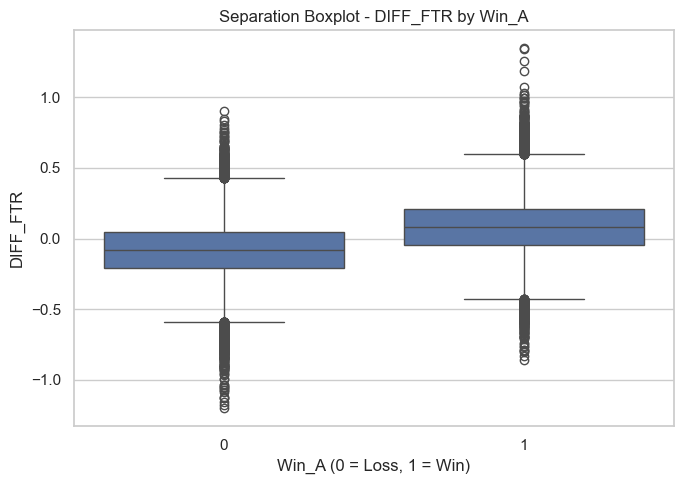

In [7]:
# Block B1 - Boxplots for top two

for feat in top2:
    plt.figure(figsize=(7, 5))
    sns.boxplot(x="Win_A", y=feat, data=master_df)
    plt.title(f"Separation Boxplot - {feat} by Win_A")
    plt.xlabel("Win_A (0 = Loss, 1 = Win)")
    plt.ylabel(feat)
    plt.tight_layout()
    plt.show()


Part C - Seed Geography Heatmap

In [8]:
#Block C1 - Extract numeric seed

seeds_df = seeds_df.copy()
seeds_df["Seed_Num"] = seeds_df["Seed"].astype(str).str.extract(r"(\d{2})").astype(int)
seeds_df.head()


,Season,Seed,TeamID,Seed_Num
0,1985,W01,1207,1
1,1985,W02,1210,2
2,1985,W03,1228,3
3,1985,W04,1260,4
4,1985,W05,1374,5


In [9]:
#Block C2 - Filter tournament games + compute winner/loser TeamID

tourney_df = master_df[master_df["Is_Tourney"] == 1].copy()

tourney_df["WTeamID"] = np.where(tourney_df["Win_A"] == 1, tourney_df["TeamA_ID"], tourney_df["TeamB_ID"])
tourney_df["LTeamID"] = np.where(tourney_df["Win_A"] == 1, tourney_df["TeamB_ID"], tourney_df["TeamA_ID"])

tourney_df[["Season","WTeamID","LTeamID"]].head()


,Season,WTeamID,LTeamID
118882,2003,1421,1411
118883,2003,1112,1436
118884,2003,1113,1272
118885,2003,1141,1166
118886,2003,1143,1301


In [10]:
#Block C3 - Merge seeds + create heatmap matrix

seed_lookup = seeds_df[["Season", "TeamID", "Seed_Num"]]

seeded = tourney_df.merge(
    seed_lookup, left_on=["Season", "WTeamID"], right_on=["Season", "TeamID"], how="left"
).rename(columns={"Seed_Num":"Winner_Seed"}).drop(columns=["TeamID"])

seeded = seeded.merge(
    seed_lookup, left_on=["Season", "LTeamID"], right_on=["Season", "TeamID"], how="left"
).rename(columns={"Seed_Num":"Loser_Seed"}).drop(columns=["TeamID"])

seeded = seeded.dropna(subset=["Winner_Seed","Loser_Seed"]).copy()
seeded["Winner_Seed"] = seeded["Winner_Seed"].astype(int)
seeded["Loser_Seed"]  = seeded["Loser_Seed"].astype(int)

seeded[["Season","Winner_Seed","Loser_Seed"]].head()


,Season,Winner_Seed,Loser_Seed
0,2003,16,16
1,2003,1,16
2,2003,10,7
3,2003,11,6
4,2003,8,9


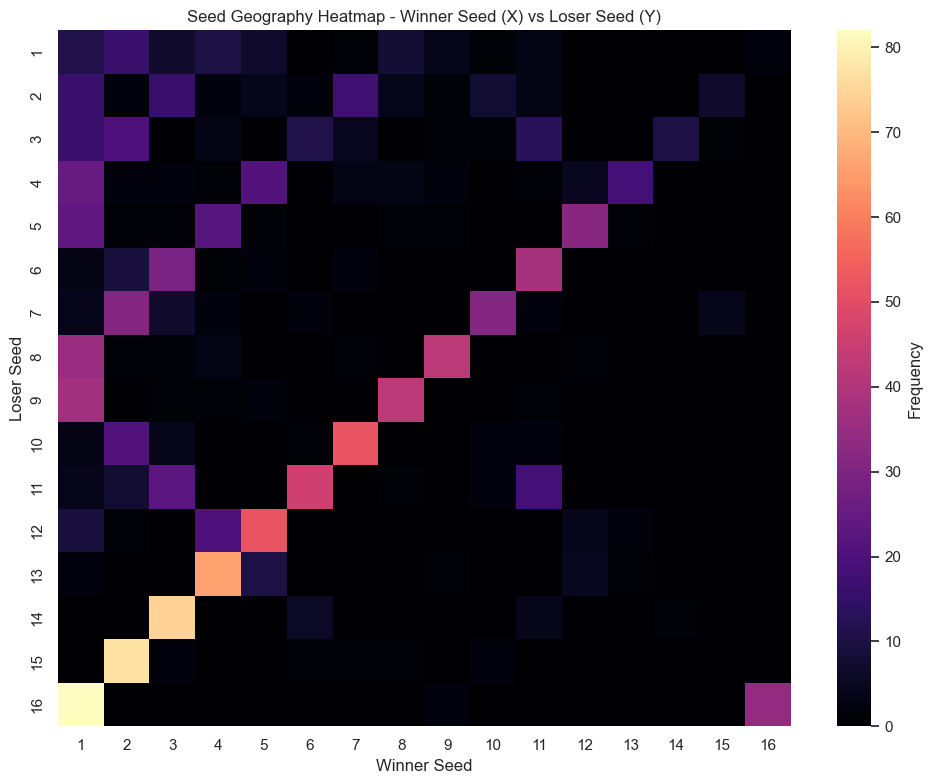

In [11]:
# Block C4 - Plot heatmap
heat = seeded.pivot_table(index="Loser_Seed", columns="Winner_Seed", aggfunc="size", fill_value=0)
heat = heat.reindex(index=range(1,17), columns=range(1,17), fill_value=0)

plt.figure(figsize=(10, 8))
sns.heatmap(heat, cmap="magma", cbar_kws={"label":"Frequency"})
plt.title("Seed Geography Heatmap - Winner Seed (X) vs Loser Seed (Y)")
plt.xlabel("Winner Seed")
plt.ylabel("Loser Seed")
plt.tight_layout()
plt.show()


Part D - Time for UPSETTTT

In [12]:
# Block D1 - Find biggest upset
seeded["Seed_Diff"] = seeded["Winner_Seed"] - seeded["Loser_Seed"]

upsets = seeded[seeded["Seed_Diff"] > 0].copy()
upsets_sorted = upsets.sort_values("Seed_Diff", ascending=False)

print("Top 5 upsets:")
display(upsets_sorted[["Season","Winner_Seed","Loser_Seed","Seed_Diff","WTeamID","LTeamID"]].head(5))

biggest = upsets_sorted.iloc[0].copy()
biggest


Season         2023.000000
Is_Tourney        1.000000
TeamA_ID       1192.000000
TeamB_ID       1345.000000
DIFF_EFG          0.037888
DIFF_TOV        -11.704389
DIFF_ORB         -0.101961
DIFF_FTR         -0.197200
Win_A             1.000000
WTeamID        1192.000000
LTeamID        1345.000000
Winner_Seed      16.000000
Loser_Seed        1.000000
Seed_Diff        15.000000
Name: 1271, dtype: float64

In [13]:
# Block D2 - Create “Winner - Loser” factor
row = biggest

# get the original MAT row
season = int(row["Season"])
winner = int(row["WTeamID"])
loser  = int(row["LTeamID"])

mask = (master_df["Season"] == season) & (
    ((master_df["TeamA_ID"] == winner) & (master_df["TeamB_ID"] == loser)) |
    ((master_df["TeamA_ID"] == loser)  & (master_df["TeamB_ID"] == winner))
)

game = master_df.loc[mask].iloc[0].copy()

flip = 1
if int(game["TeamA_ID"]) == loser:
    flip = -1

autopsy = pd.Series({
    "Season": season,
    "Winner_Seed": int(row["Winner_Seed"]),
    "Loser_Seed": int(row["Loser_Seed"]),
    "Seed_Diff": int(row["Seed_Diff"]),
    "DIFF_EFG (Winner-Loser)": float(flip * game["DIFF_EFG"]),
    "DIFF_TOV (Winner-Loser)": float(flip * game["DIFF_TOV"]),
    "DIFF_ORB (Winner-Loser)": float(flip * game["DIFF_ORB"]),
    "DIFF_FTR (Winner-Loser)": float(flip * game["DIFF_FTR"]),
})

autopsy


Season                     2023.000000
Winner_Seed                  16.000000
Loser_Seed                    1.000000
Seed_Diff                    15.000000
DIFF_EFG (Winner-Loser)       0.037888
DIFF_TOV (Winner-Loser)     -11.704389
DIFF_ORB (Winner-Loser)      -0.101961
DIFF_FTR (Winner-Loser)      -0.197200
dtype: float64